# When do people rent Citi Bikes at E 2 St & Avenue B?
This notebook loads one month of Citi Bike trips (August 2015) that started at one station in Manhattan, counts trips by hour of day, and compares weekdays with weekends.

## Step 1. Load the data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

trips = pd.read_csv('data/citibike.csv', parse_dates=['starttime', 'stoptime'])
print('Number of trips:', len(trips))
print('First trip:', trips['starttime'].min())
print('Last trip:', trips['starttime'].max())
trips.head()

Number of trips: 4212
First trip: 2015-08-01 01:19:15
Last trip: 2015-08-31 23:53:03


,tripduration,starttime,stoptime,start station id,start station name,start station latitude,start station longitude,end station id,end station name,end station latitude,end station longitude,bikeid,usertype,birth year,gender
0,3117,2015-08-01 01:19:15,2015-08-01 02:11:12,301,E 2 St & Avenue B,40.722174,-73.983688,301,E 2 St & Avenue B,40.722174,-73.983688,18070,Subscriber,1986.0,1
1,690,2015-08-01 01:27:30,2015-08-01 01:39:00,301,E 2 St & Avenue B,40.722174,-73.983688,349,Rivington St & Ridge St,40.718502,-73.983299,19699,Subscriber,1985.0,1
2,727,2015-08-01 01:38:49,2015-08-01 01:50:57,301,E 2 St & Avenue B,40.722174,-73.983688,2010,Grand St & Greene St,40.721655,-74.002347,20953,Subscriber,1982.0,1
3,698,2015-08-01 06:06:41,2015-08-01 06:18:20,301,E 2 St & Avenue B,40.722174,-73.983688,527,E 33 St & 2 Ave,40.744023,-73.976056,23566,Subscriber,1976.0,1
4,351,2015-08-01 06:24:29,2015-08-01 06:30:21,301,E 2 St & Avenue B,40.722174,-73.983688,250,Lafayette St & Jersey St,40.724561,-73.995653,17545,Subscriber,1959.0,1


Save the first few rows as `input_example.png` for the README.

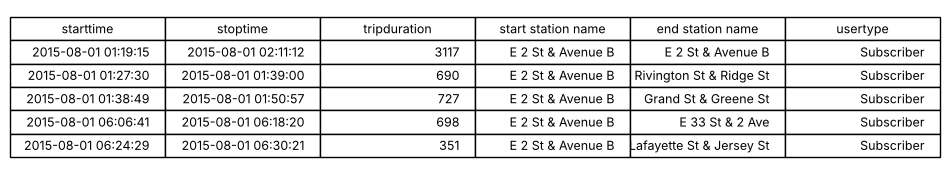

In [2]:
cols = ['starttime', 'stoptime', 'tripduration', 'start station name', 'end station name', 'usertype']
preview = trips[cols].head(5).astype(str)

fig, ax = plt.subplots(figsize=(12, 2))
ax.axis('off')
table = ax.table(cellText=preview.values, colLabels=cols, loc='center')
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.4)
plt.savefig('input_example.png', dpi=150, bbox_inches='tight')
plt.show()

## Step 2. Count trips per hour
Each row is one trip. We count how many trips started in each hour of each day. Hours with no trips get a count of 0.

In [3]:
trips['date'] = trips['starttime'].dt.date
trips['hour'] = trips['starttime'].dt.hour

# rows = days, columns = hours 0-23, values = number of trips
counts = pd.crosstab(trips['date'], trips['hour'])
counts = counts.reindex(columns=range(24), fill_value=0)
counts.head()

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
date,,,,,,,,,,,,,,,,,,,,,
2015-08-01,0,3,0,0,0,0,2,1,6,15,...,11,5,15,7,7,2,3,3,1,0
2015-08-02,0,1,2,1,2,1,3,0,3,6,...,9,11,10,6,10,11,7,2,4,0
2015-08-03,0,1,2,0,0,2,7,10,4,3,...,2,3,7,4,13,9,6,7,2,4
2015-08-04,0,0,0,0,0,2,6,18,26,5,...,1,2,11,10,11,9,6,4,4,6
2015-08-05,0,0,0,2,0,1,8,26,8,3,...,5,7,10,14,10,12,1,11,3,1


## Step 3. Compare weekdays and weekends

Weekdays: 21  Weekend days: 10


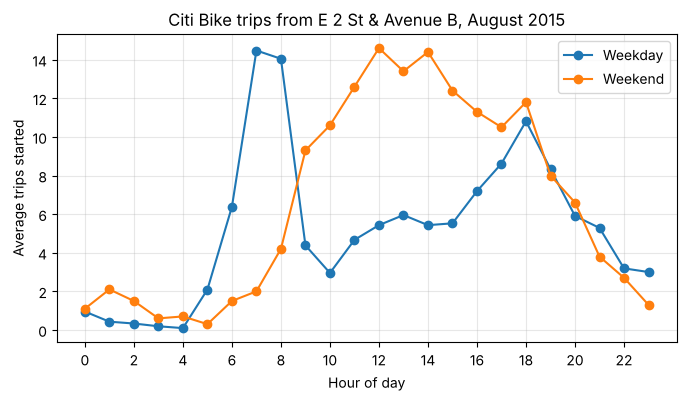

In [4]:
is_weekend = pd.to_datetime(counts.index).dayofweek >= 5   # Saturday = 5, Sunday = 6
weekday_avg = counts[~is_weekend].mean()
weekend_avg = counts[is_weekend].mean()
print('Weekdays:', (~is_weekend).sum(), ' Weekend days:', is_weekend.sum())

plt.figure(figsize=(8, 4))
plt.plot(weekday_avg.index, weekday_avg.values, marker='o', label='Weekday')
plt.plot(weekend_avg.index, weekend_avg.values, marker='o', label='Weekend')
plt.xticks(range(0, 24, 2))
plt.xlabel('Hour of day')
plt.ylabel('Average trips started')
plt.title('Citi Bike trips from E 2 St & Avenue B, August 2015')
plt.legend()
plt.grid(alpha=0.3)
plt.savefig('output_example.png', dpi=150, bbox_inches='tight')
plt.show()

## Step 4. Check the results

In [5]:
# The hourly counts should add up to the number of trips we loaded.
print('Trips loaded:', len(trips))
print('Sum of hourly counts:', counts.values.sum())

# Busiest hour on weekdays and on weekends
print('Busiest weekday hour:', weekday_avg.idxmax(), 'with', round(weekday_avg.max(), 1), 'trips on average')
print('Busiest weekend hour:', weekend_avg.idxmax(), 'with', round(weekend_avg.max(), 1), 'trips on average')

Trips loaded: 4212
Sum of hourly counts: 4212
Busiest weekday hour: 7 with 14.5 trips on average
Busiest weekend hour: 12 with 14.6 trips on average
